# Loan Delinquent Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import warnings

from sklearn.model_selection import GridSearchCV, train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
)
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")

In [2]:
raw_df = pd.read_csv("Loan_Delinquent_Dataset.csv")
raw_df.shape

(11548, 8)

In [3]:
df = raw_df.copy()

In [4]:
df.head()

,ID,isDelinquent,term,gender,purpose,home_ownership,age,FICO
0,1,1,36 months,Female,House,Mortgage,>25,300-500
1,2,0,36 months,Female,House,Rent,20-25,>500
2,3,1,36 months,Female,House,Rent,>25,300-500
3,4,1,36 months,Female,Car,Mortgage,>25,300-500
4,5,1,36 months,Female,House,Rent,>25,300-500


In [5]:
df.tail()

,ID,isDelinquent,term,gender,purpose,home_ownership,age,FICO
11543,11544,0,60 months,Male,other,Mortgage,>25,300-500
11544,11545,1,36 months,Male,House,Rent,20-25,300-500
11545,11546,0,36 months,Female,Personal,Mortgage,20-25,>500
11546,11547,1,36 months,Female,House,Rent,20-25,300-500
11547,11548,1,36 months,Male,Personal,Mortgage,20-25,300-500


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11548 entries, 0 to 11547
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   ID              11548 non-null  int64
 1   isDelinquent    11548 non-null  int64
 2   term            11548 non-null  str  
 3   gender          11548 non-null  str  
 4   purpose         11548 non-null  str  
 5   home_ownership  11548 non-null  str  
 6   age             11548 non-null  str  
 7   FICO            11548 non-null  str  
dtypes: int64(2), str(6)
memory usage: 721.9 KB


In [7]:
for col in ["term", "gender", "purpose", "home_ownership", "age", "FICO", "isDelinquent"]:
    df[col] = df[col].astype("category")

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11548 entries, 0 to 11547
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   ID              11548 non-null  int64   
 1   isDelinquent    11548 non-null  category
 2   term            11548 non-null  category
 3   gender          11548 non-null  category
 4   purpose         11548 non-null  category
 5   home_ownership  11548 non-null  category
 6   age             11548 non-null  category
 7   FICO            11548 non-null  category
dtypes: category(7), int64(1)
memory usage: 169.6 KB


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.isnull().sum()

ID                0
isDelinquent      0
term              0
gender            0
purpose           0
home_ownership    0
age               0
FICO              0
dtype: int64

In [11]:
df.describe(include="all")

,ID,isDelinquent,term,gender,purpose,home_ownership,age,FICO
count,11548.000000,11548.0,11548,11548,11548,11548,11548,11548
unique,NaN,2.0,2,2,7,3,2,2
top,NaN,1.0,36 months,Male,House,Mortgage,20-25,300-500
freq,NaN,7721.0,10589,6555,6892,5461,5888,6370
mean,5774.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,3333.764789,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,2887.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,5774.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,8661.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
df["ID"].nunique()

11548

In [13]:
df = df.drop("ID", axis=1)

In [14]:
df["purpose"].unique()

['House', 'Car', 'Other', 'Personal', 'Wedding', 'Medical', 'other']
Categories (7, str): ['Car', 'House', 'Medical', 'Other', 'Personal', 'Wedding', 'other']

In [15]:
df["purpose"] = df["purpose"].replace("other", "Other").cat.remove_unused_categories()

In [16]:
df["purpose"].unique()

['House', 'Car', 'Other', 'Personal', 'Wedding', 'Medical']
Categories (6, str): ['Car', 'House', 'Medical', 'Other', 'Personal', 'Wedding']

In [17]:
def bar_with_labels(data, feature, perc=True):
    total = len(data[feature])
    levels = data[feature].nunique()
    plt.figure(figsize=(levels + 2, 5))
    plt.xticks(rotation=90, fontsize=12)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Set2",
        order=data[feature].value_counts().index.sort_values(),
    )
    for p in ax.patches:
        if perc:
            label = "{:.1f}%".format(100 * p.get_height() / total)
        else:
            label = p.get_height()
        ax.annotate(
            label,
            (p.get_x() + p.get_width() / 2, p.get_height()),
            ha="center",
            va="center",
            size=11,
            xytext=(0, 5),
            textcoords="offset points",
        )
    plt.show()

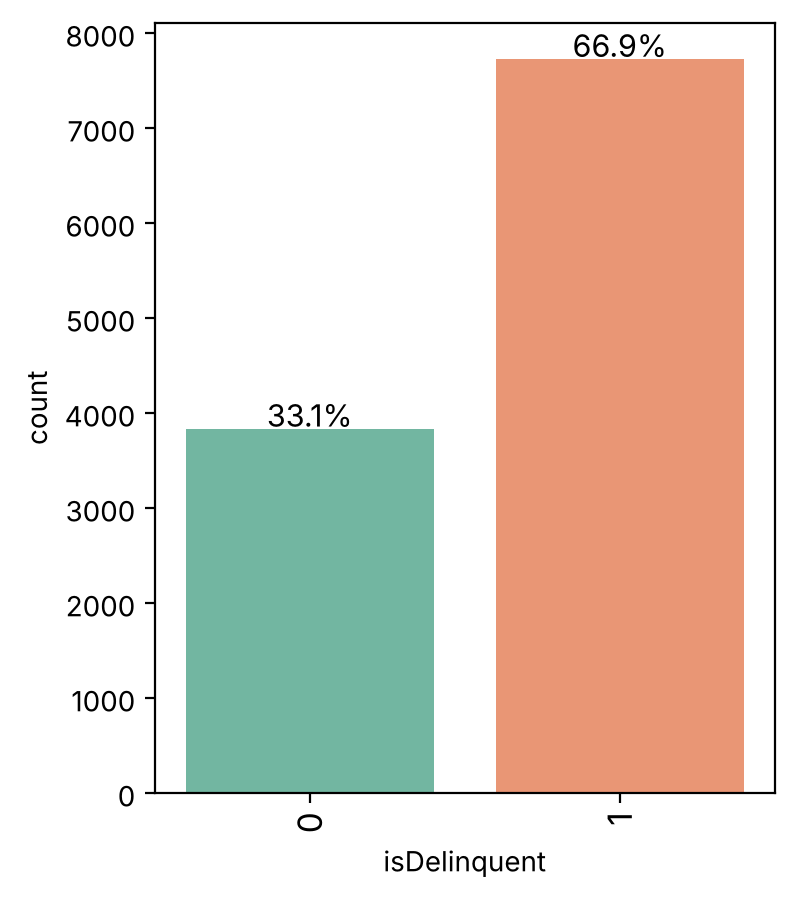

In [18]:
bar_with_labels(df, "isDelinquent")

* About 67% of the customers are delinquent and 33% are not.

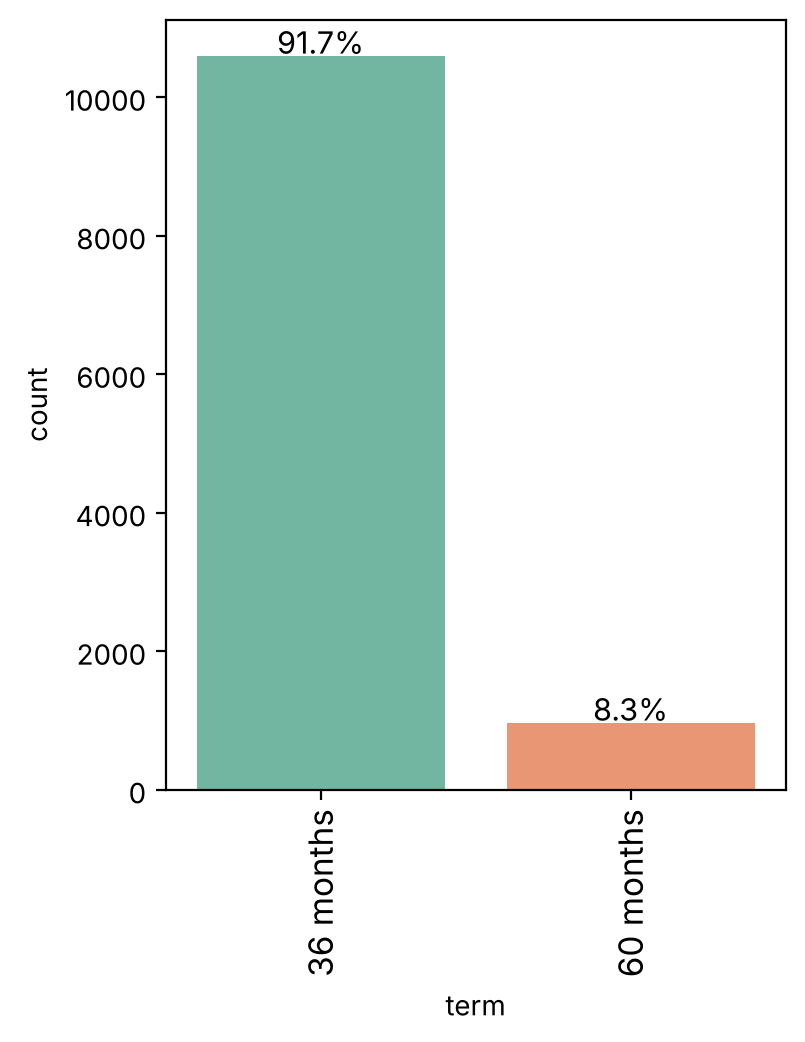

In [19]:
bar_with_labels(df, "term")

* Around 92% of the loans are for 36 months. Only 8% are for 60 months.

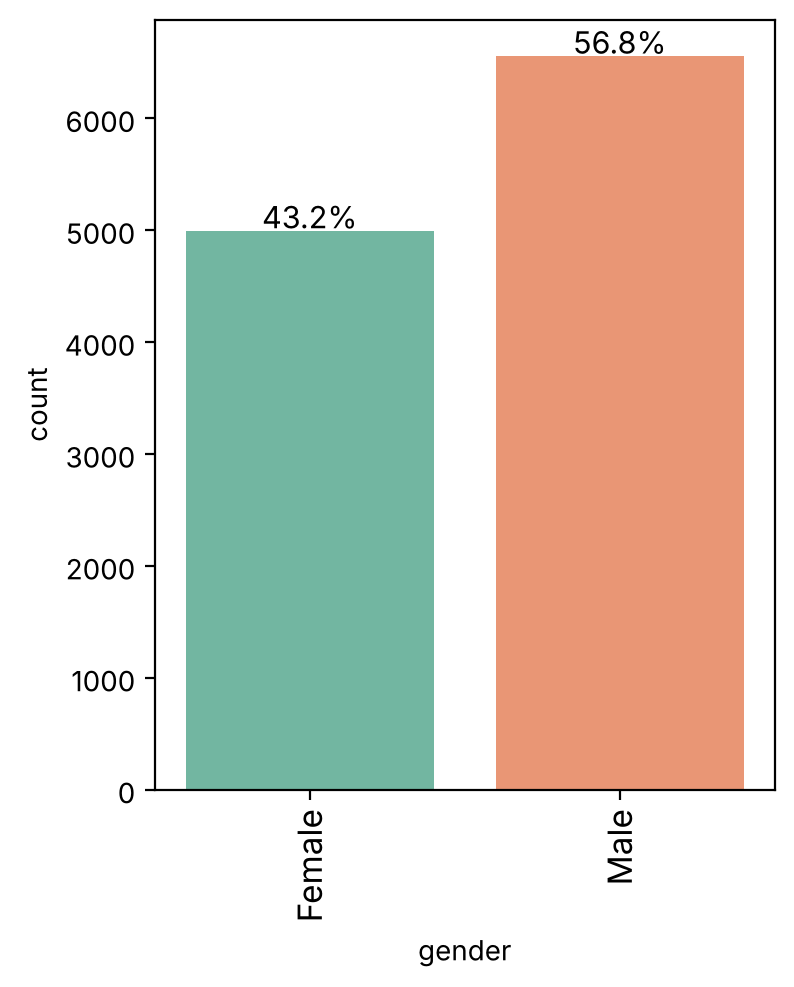

In [20]:
bar_with_labels(df, "gender")

* There are more male customers (56.8%) than female customers (43.2%).

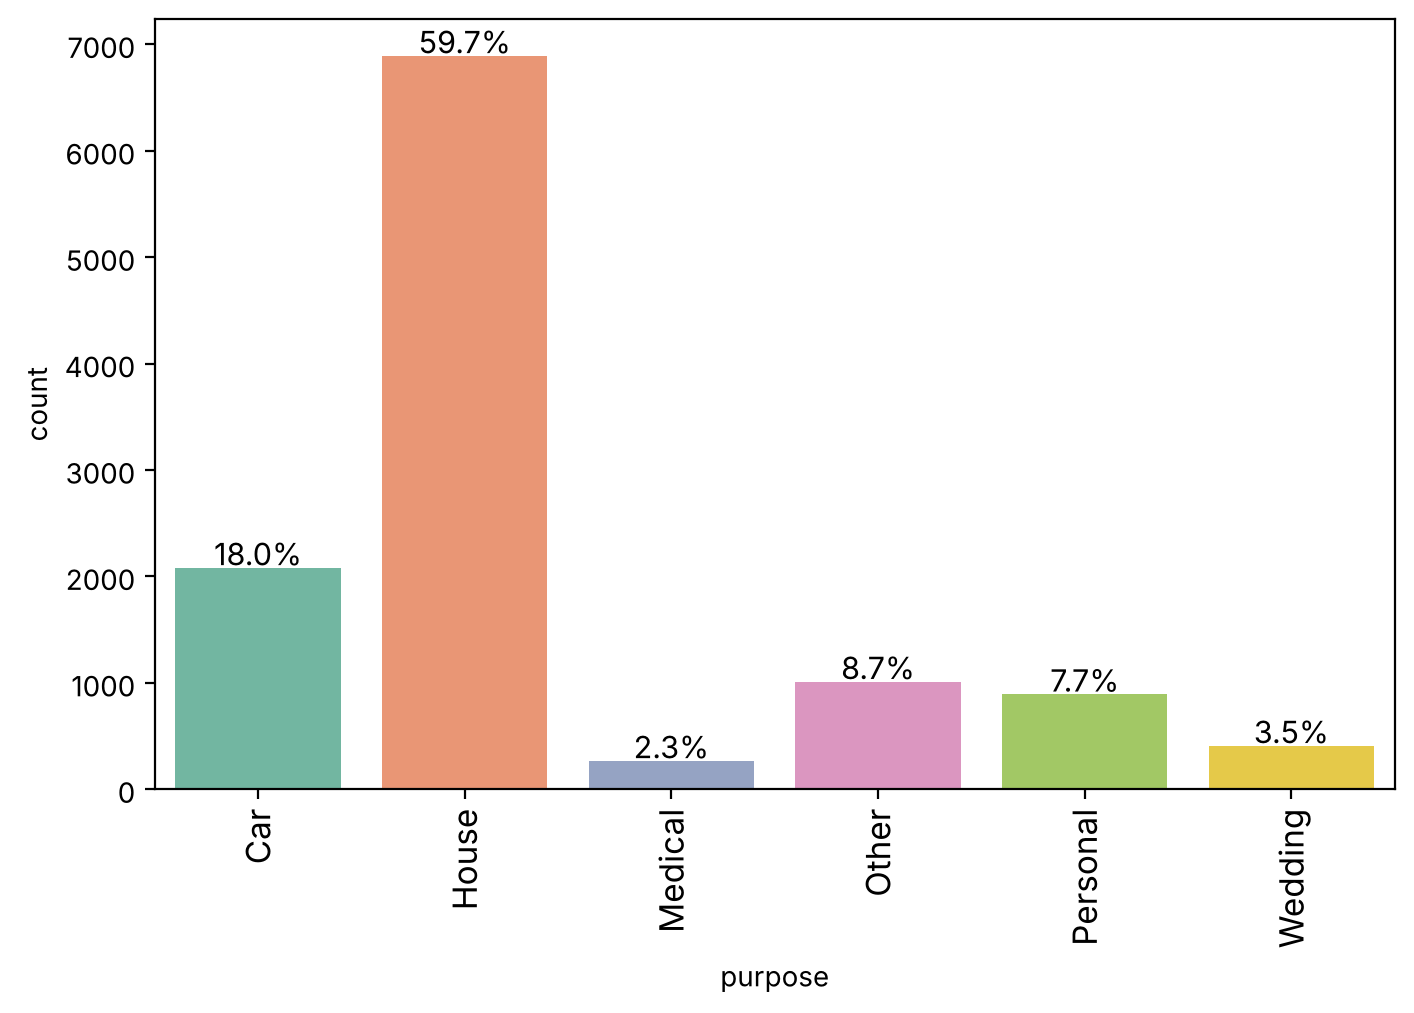

In [21]:
bar_with_labels(df, "purpose")

* House loan is the most common (59.7%) and then car loan (18%). Medical and wedding loans are the least.

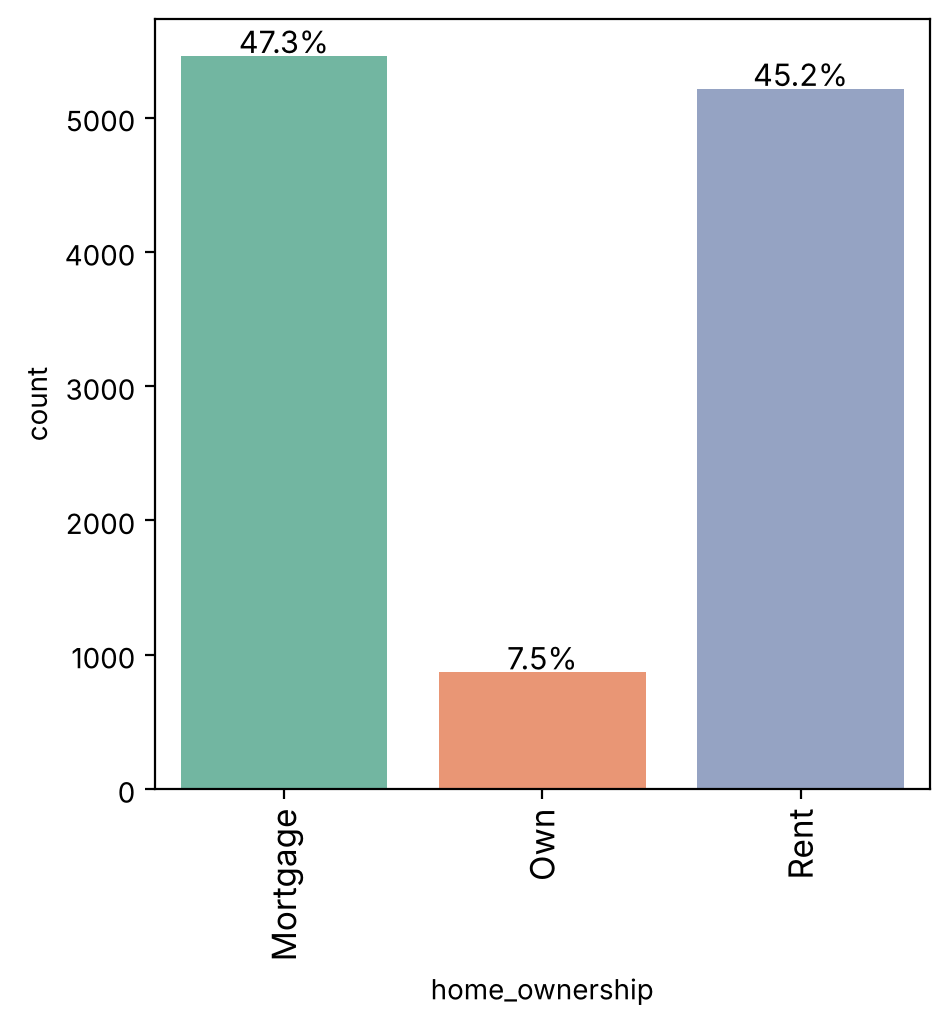

In [22]:
bar_with_labels(df, "home_ownership")

* Mortgage (47%) and rent (45%) are almost the same. Only 7.5% of the customers own a house.

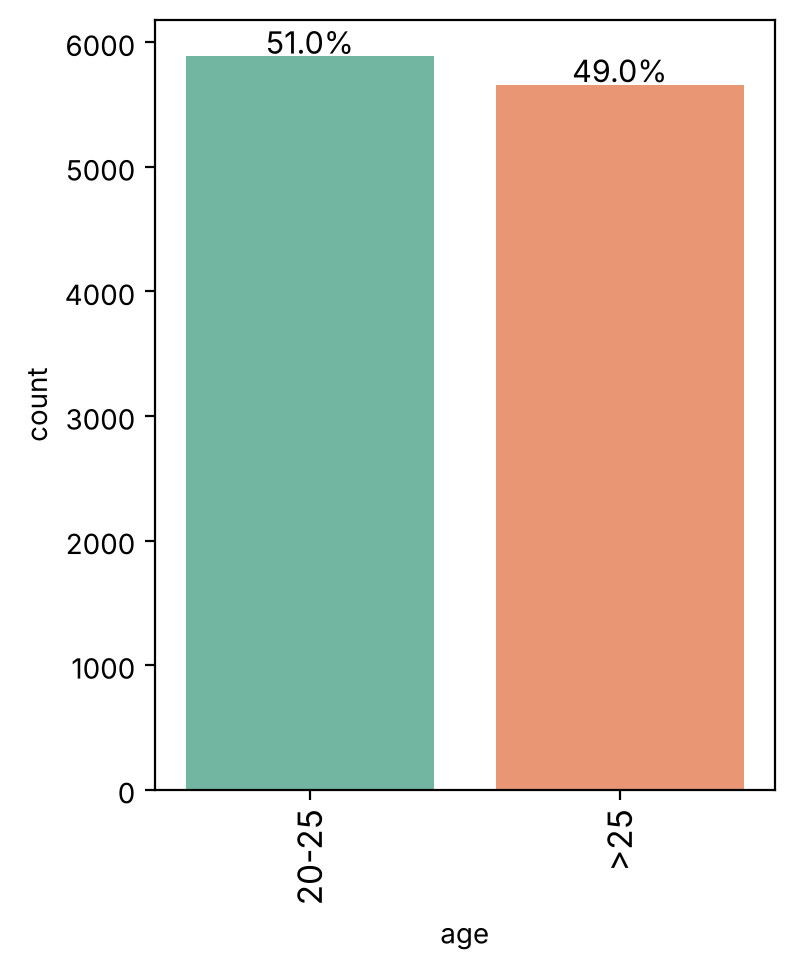

In [23]:
bar_with_labels(df, "age")

* Both age groups are almost equal. 20-25 is 51% and above 25 is 49%.

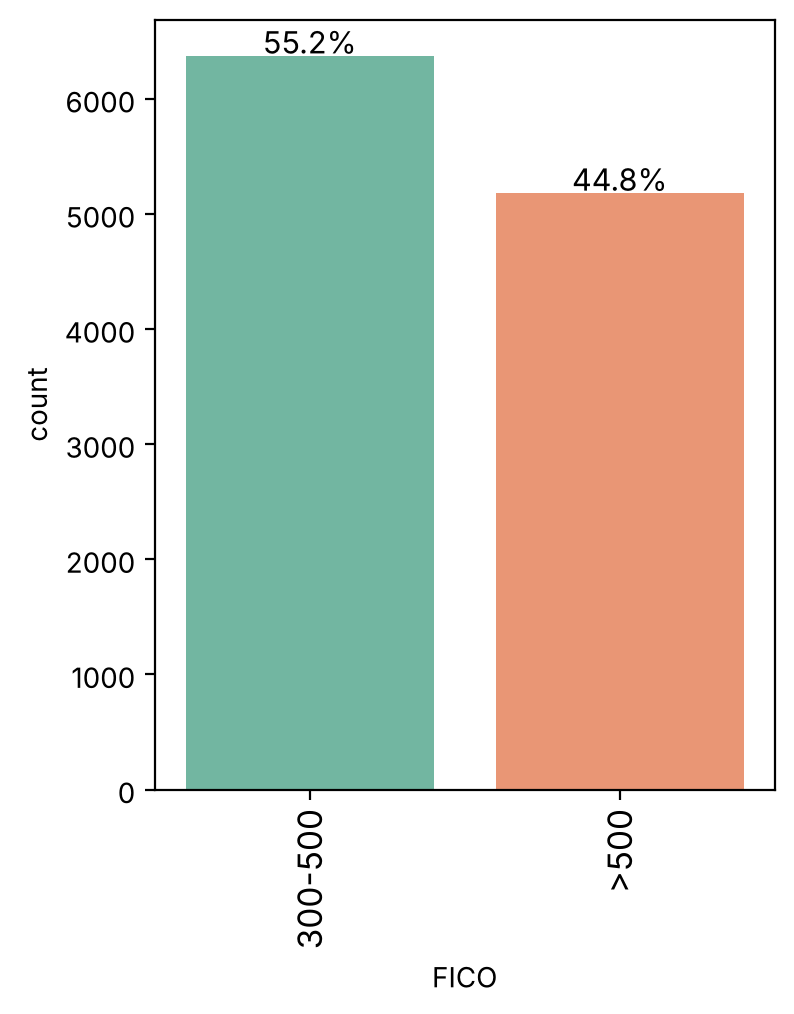

In [24]:
bar_with_labels(df, "FICO")

* 55% of the customers have a FICO score of 300-500 and 45% have above 500.

In [25]:
def stacked_bar(data, predictor, target):
    levels = data[predictor].nunique()
    last = data[target].value_counts().index[-1]
    counts = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=last, ascending=False
    )
    print(counts)
    print("-" * 80)
    share = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=last, ascending=False
    )
    share.plot(kind="bar", stacked=True, figsize=(levels + 2, 5), colormap="Set2")
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

isDelinquent     0     1    All
term                           
All           3827  7721  11548
36 months     3168  7421  10589
60 months      659   300    959
--------------------------------------------------------------------------------


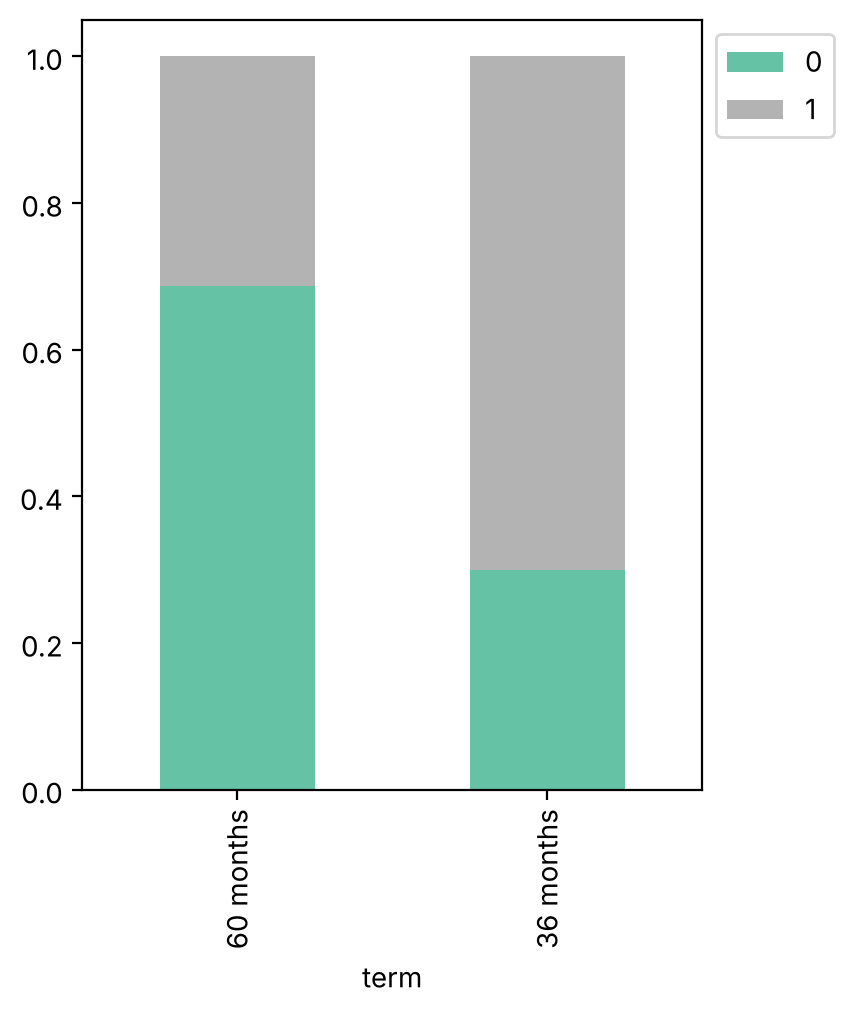

In [26]:
stacked_bar(df, "term", "isDelinquent")

* 36 months loans have 70% delinquency but 60 months loans have only 31%.

isDelinquent     0     1    All
gender                         
All           3827  7721  11548
Male          1977  4578   6555
Female        1850  3143   4993
--------------------------------------------------------------------------------


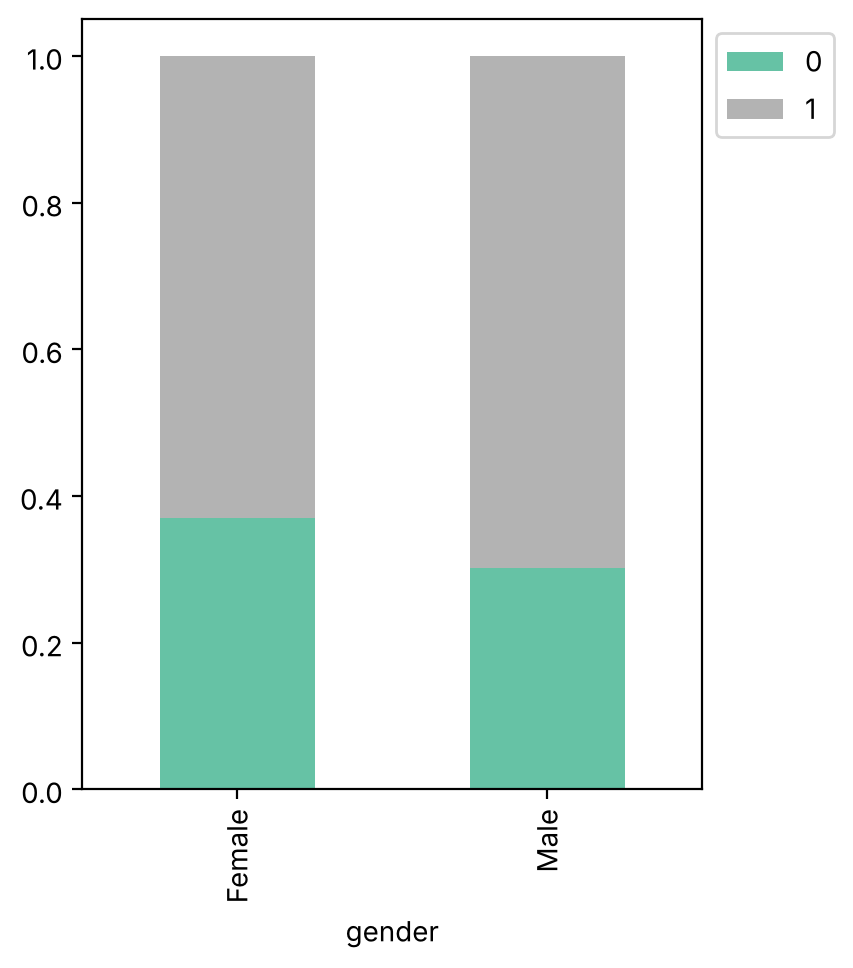

In [27]:
stacked_bar(df, "gender", "isDelinquent")

* Males are a little more delinquent (70%) than females (63%).

isDelinquent     0     1    All
purpose                        
All           3827  7721  11548
House         2272  4620   6892
Car            678  1402   2080
Other          357   653   1010
Personal       274   618    892
Wedding        139   269    408
Medical        107   159    266
--------------------------------------------------------------------------------


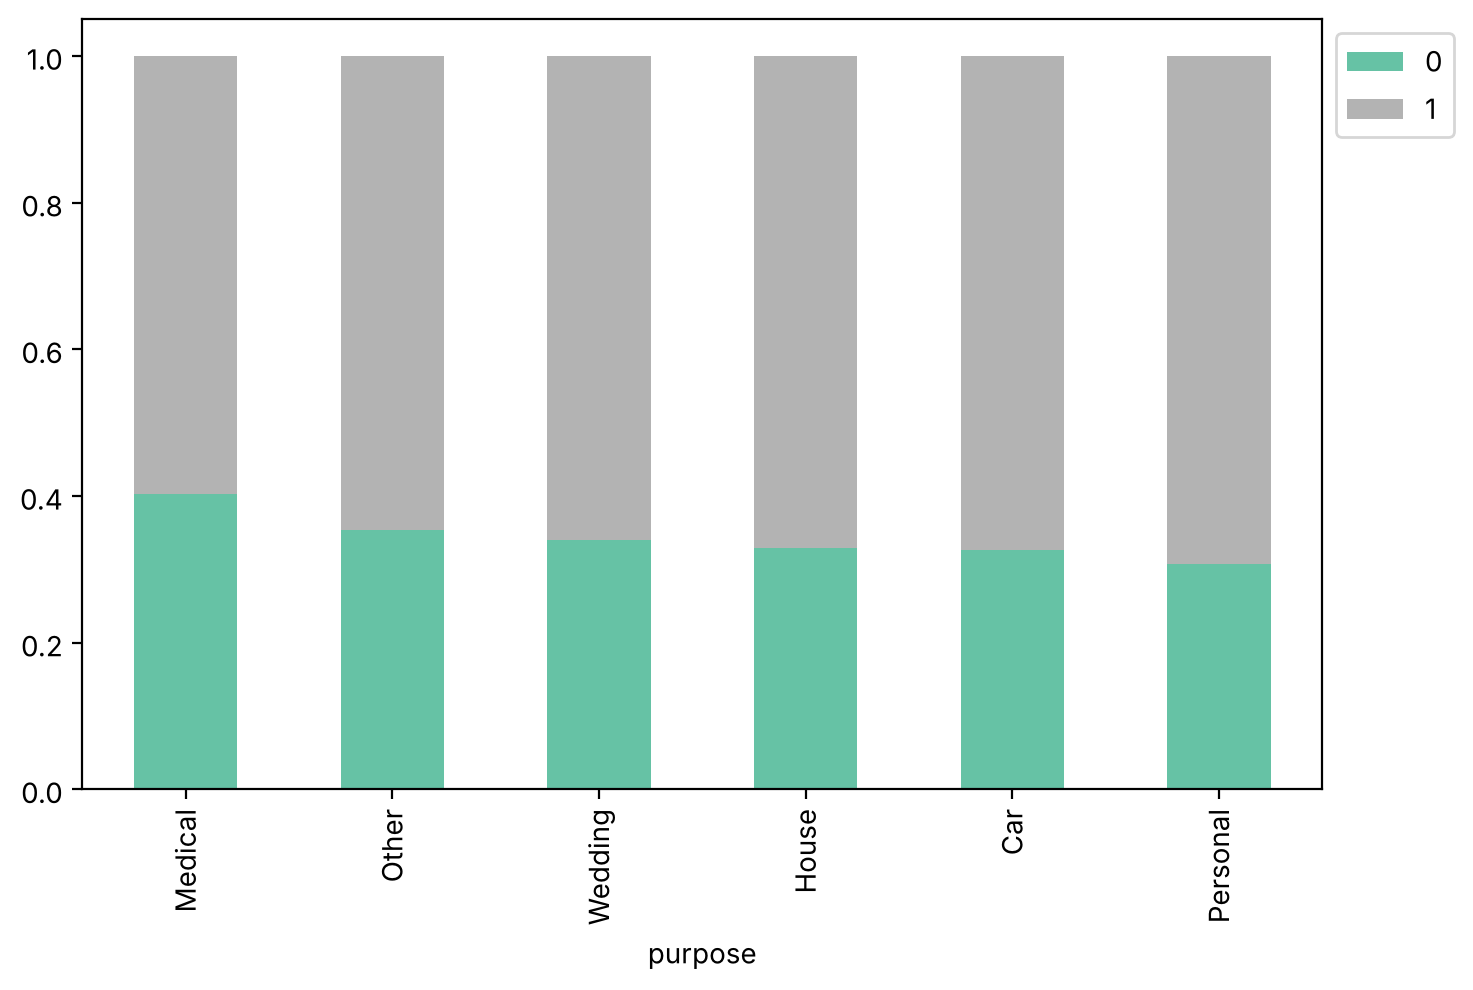

In [28]:
stacked_bar(df, "purpose", "isDelinquent")

* Delinquency is around 65-70% for most of the purposes. Medical is the lowest (60%).

isDelinquent       0     1    All
home_ownership                   
All             3827  7721  11548
Mortgage        1831  3630   5461
Rent            1737  3479   5216
Own              259   612    871
--------------------------------------------------------------------------------


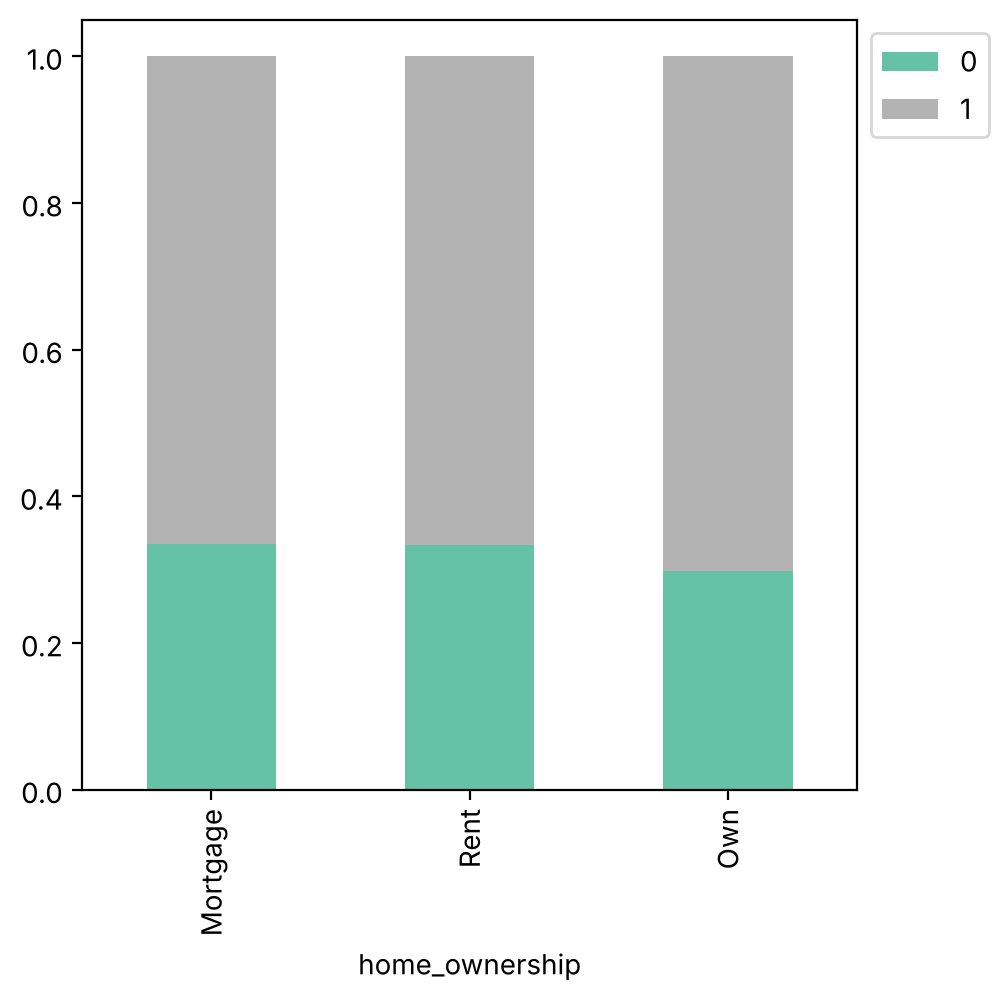

In [29]:
stacked_bar(df, "home_ownership", "isDelinquent")

* All three are close to each other (around 67-70%). Own is slightly higher at 70%.

isDelinquent     0     1    All
age                            
All           3827  7721  11548
>25           1969  3691   5660
20-25         1858  4030   5888
--------------------------------------------------------------------------------


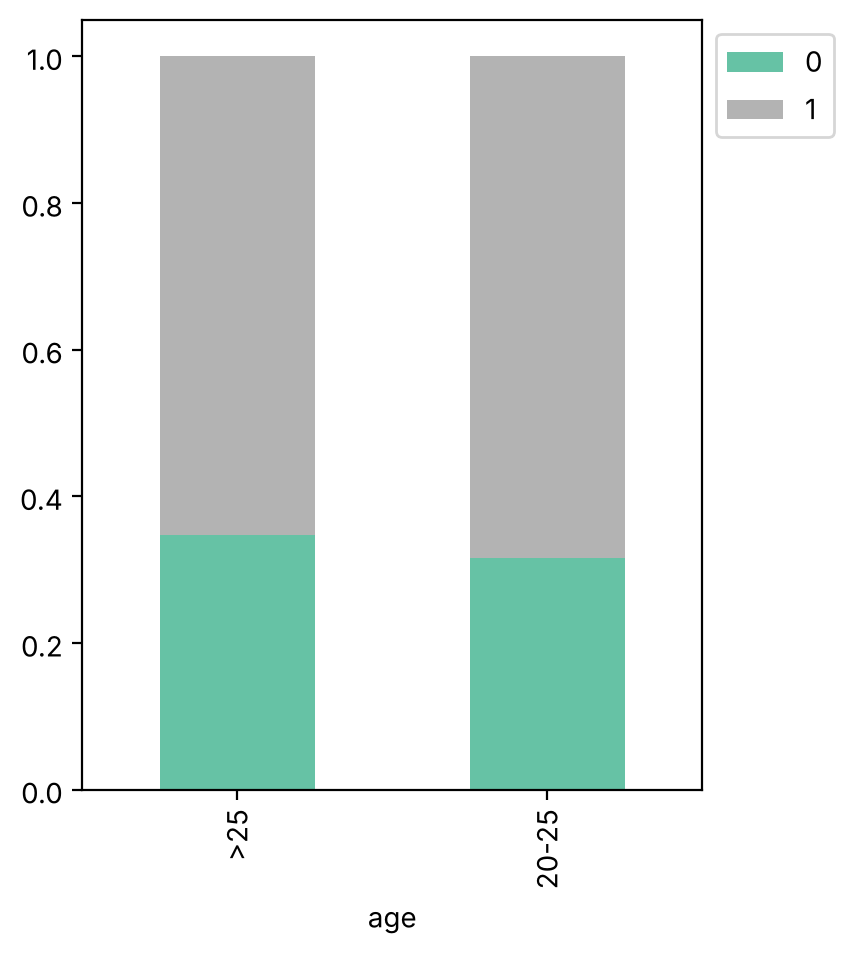

In [30]:
stacked_bar(df, "age", "isDelinquent")

* 20-25 age group is a bit more delinquent (68%) than the above 25 group (65%).

isDelinquent     0     1    All
FICO                           
All           3827  7721  11548
>500          2886  2292   5178
300-500        941  5429   6370
--------------------------------------------------------------------------------


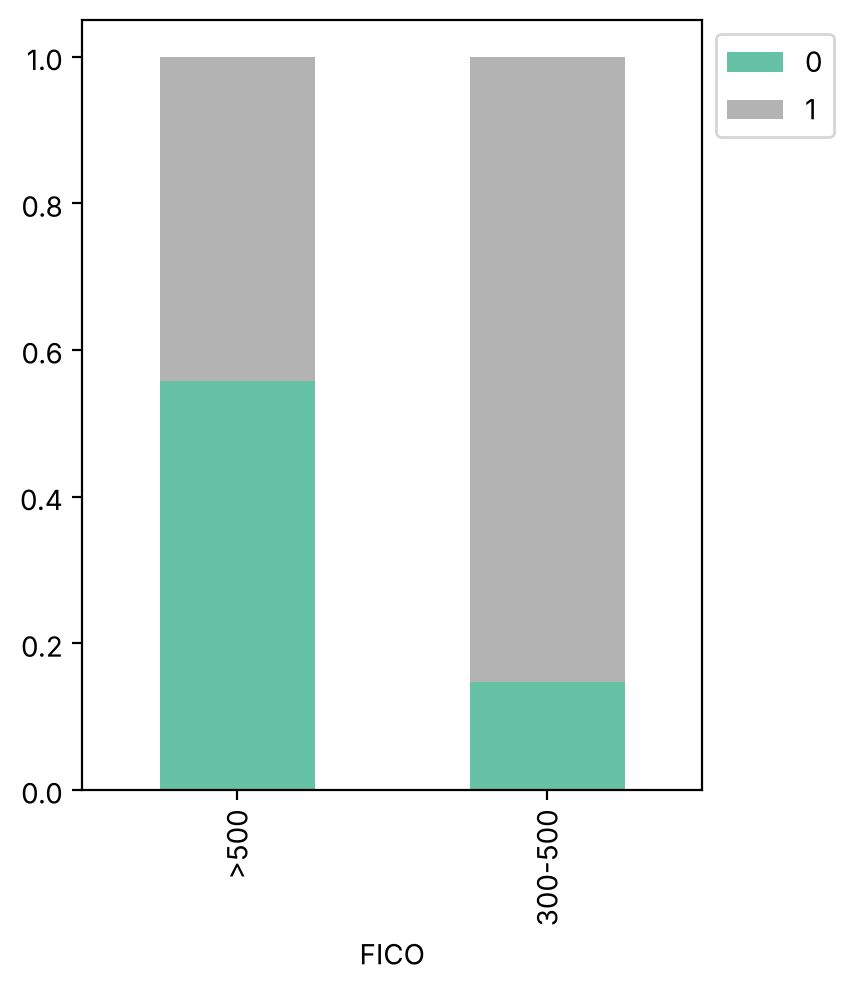

In [31]:
stacked_bar(df, "FICO", "isDelinquent")

* Customers with 300-500 FICO are 85% delinquent but with above 500 only 44%. This is a big difference.

FICO            300-500  >500    All
home_ownership                      
All                6370  5178  11548
Mortgage           2857  2604   5461
Rent               3033  2183   5216
Own                 480   391    871
--------------------------------------------------------------------------------


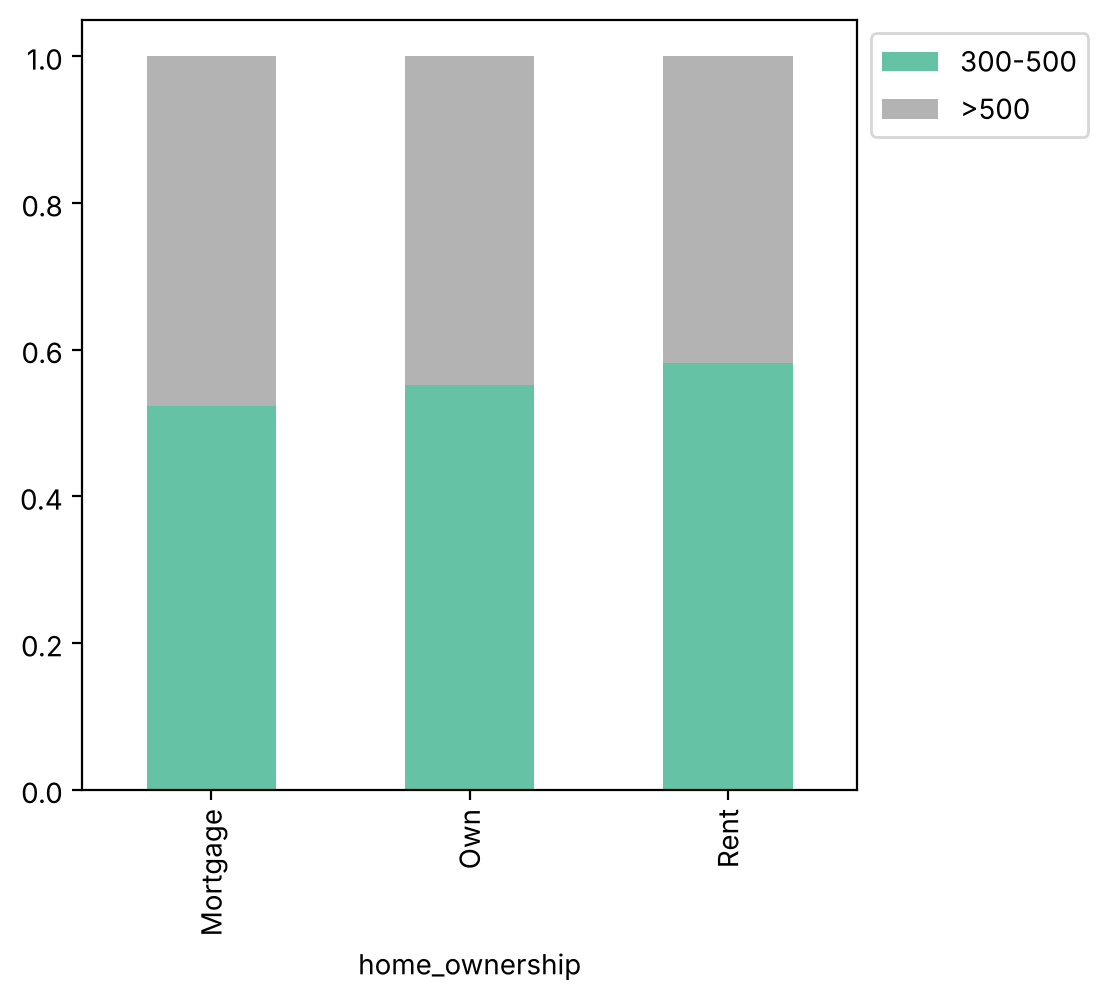

In [32]:
stacked_bar(df, "home_ownership", "FICO")

* There is not much difference. Mortgage has slightly more customers with above 500 score (48%).

FICO   300-500  >500    All
age                        
All       6370  5178  11548
>25       2443  3217   5660
20-25     3927  1961   5888
--------------------------------------------------------------------------------


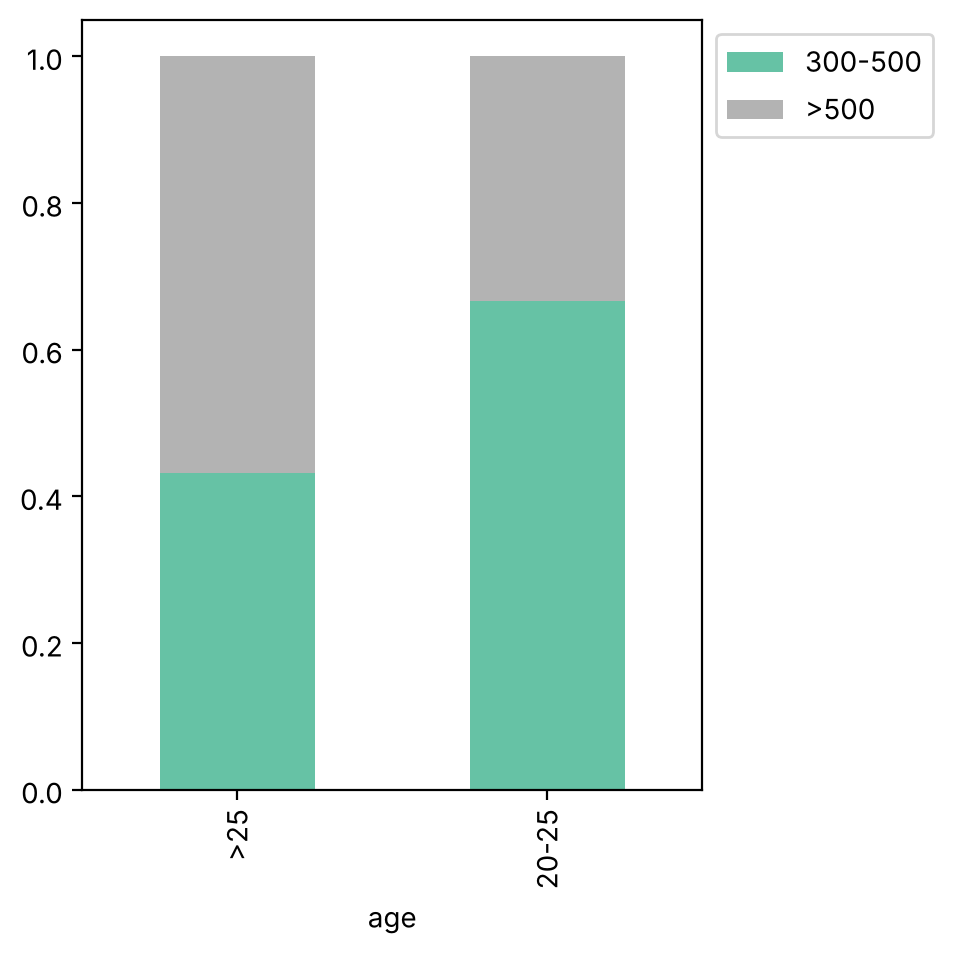

In [33]:
stacked_bar(df, "age", "FICO")

* Above 25 age group has more high scores (57%) than the 20-25 group (33%).

FICO    300-500  >500    All
gender                      
All        6370  5178  11548
Male       3705  2850   6555
Female     2665  2328   4993
--------------------------------------------------------------------------------


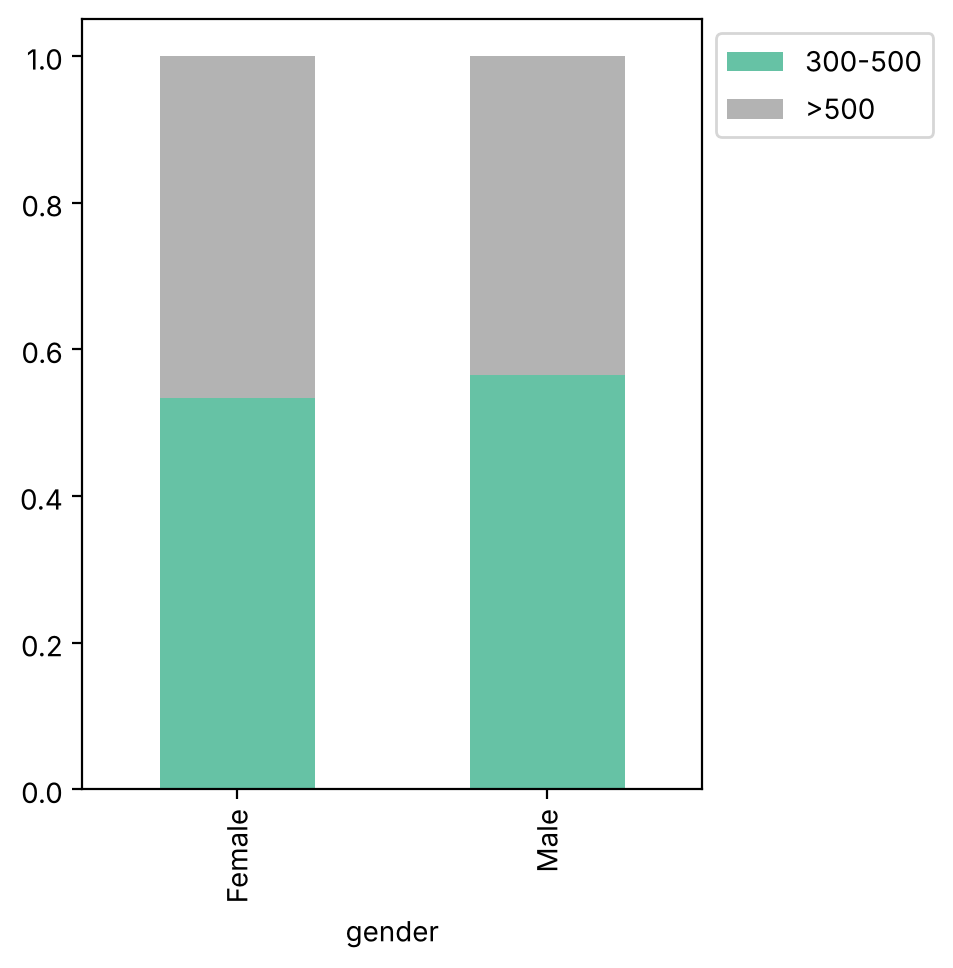

In [34]:
stacked_bar(df, "gender", "FICO")

* Females have slightly more high scores (47%) than males (44%).

In [35]:
table = pd.crosstab(df["FICO"], df["home_ownership"])
chi, p_value, dof, expected = stats.chi2_contingency(table)
if p_value < 0.05:
    print("FICO score has an effect on home_ownership, p_value =", p_value.round(3))
else:
    print("FICO score has no effect on home_ownership, p_value =", p_value.round(3))

FICO score has an effect on home_ownership, p_value = 0.0


In [36]:
table = pd.crosstab(df["FICO"], df["gender"])
chi, p_value, dof, expected = stats.chi2_contingency(table)
if p_value < 0.05:
    print("FICO score has an effect on gender, p_value =", p_value.round(3))
else:
    print("FICO score has no effect on gender, p_value =", p_value.round(3))

FICO score has an effect on gender, p_value = 0.001


In [37]:
table = pd.crosstab(df["FICO"], df["age"])
chi, p_value, dof, expected = stats.chi2_contingency(table)
if p_value < 0.05:
    print("FICO score has an effect on age, p_value =", p_value.round(3))
else:
    print("FICO score has no effect on age, p_value =", p_value.round(3))

FICO score has an effect on age, p_value = 0.0


In [38]:
x = df.drop("isDelinquent", axis=1)
y = df["isDelinquent"]
x = pd.get_dummies(x, drop_first=True, dtype=int)
x.head()

,term_60 months,gender_Male,purpose_House,purpose_Medical,purpose_Other,purpose_Personal,purpose_Wedding,home_ownership_Own,home_ownership_Rent,age_>25,FICO_>500
0,0,0,1,0,0,0,0,0,0,1,0
1,0,0,1,0,0,0,0,0,1,0,1
2,0,0,1,0,0,0,0,0,1,1,0
3,0,0,0,0,0,0,0,0,0,1,0
4,0,0,1,0,0,0,0,0,1,1,0


In [39]:
X_temp, X_test, y_temp, y_test = train_test_split(
    x, y, test_size=0.2, random_state=1, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=1, stratify=y_temp
)
print("Train rows =", X_train.shape[0])
print("Validation rows =", X_val.shape[0])
print("Test rows =", X_test.shape[0])

Train rows = 6928
Validation rows = 2310
Test rows = 2310


In [40]:
def get_scores(model, predictors, target):
    pred = model.predict(predictors)
    return pd.DataFrame(
        {
            "Accuracy": accuracy_score(target, pred),
            "Recall": recall_score(target, pred),
            "Precision": precision_score(target, pred),
            "F1": f1_score(target, pred),
        },
        index=[0],
    )

In [41]:
def plot_confusion(model, predictors, target):
    pred = model.predict(predictors)
    cm = confusion_matrix(target, pred)
    labels = np.asarray(
        ["{0:0.0f}".format(v) + "\n{0:.2%}".format(v / cm.sum()) for v in cm.flatten()]
    ).reshape(2, 2)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.show()

In [42]:
lr = LogisticRegression(random_state=1)
lr.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

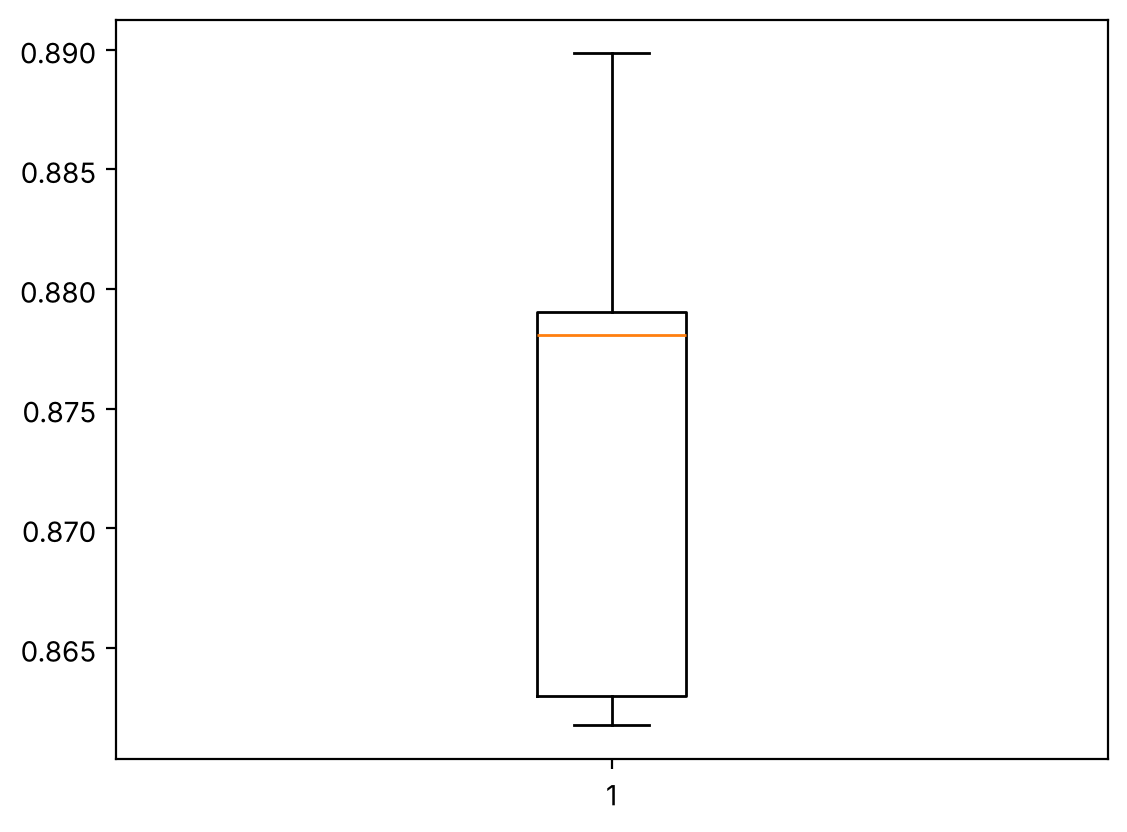

In [43]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
cv_base = cross_val_score(estimator=lr, X=X_train, y=y_train, scoring="recall", cv=kfold)
plt.boxplot(cv_base)
plt.show()

In [44]:
lr_train = get_scores(lr, X_train, y_train)
print("Training performance:")
lr_train

Training performance:


,Accuracy,Recall,Precision,F1
0,0.782621,0.872409,0.815375,0.842929


In [45]:
lr_val = get_scores(lr, X_val, y_val)
print("Validation performance:")
lr_val

Validation performance:


,Accuracy,Recall,Precision,F1
0,0.797403,0.891909,0.820727,0.854839


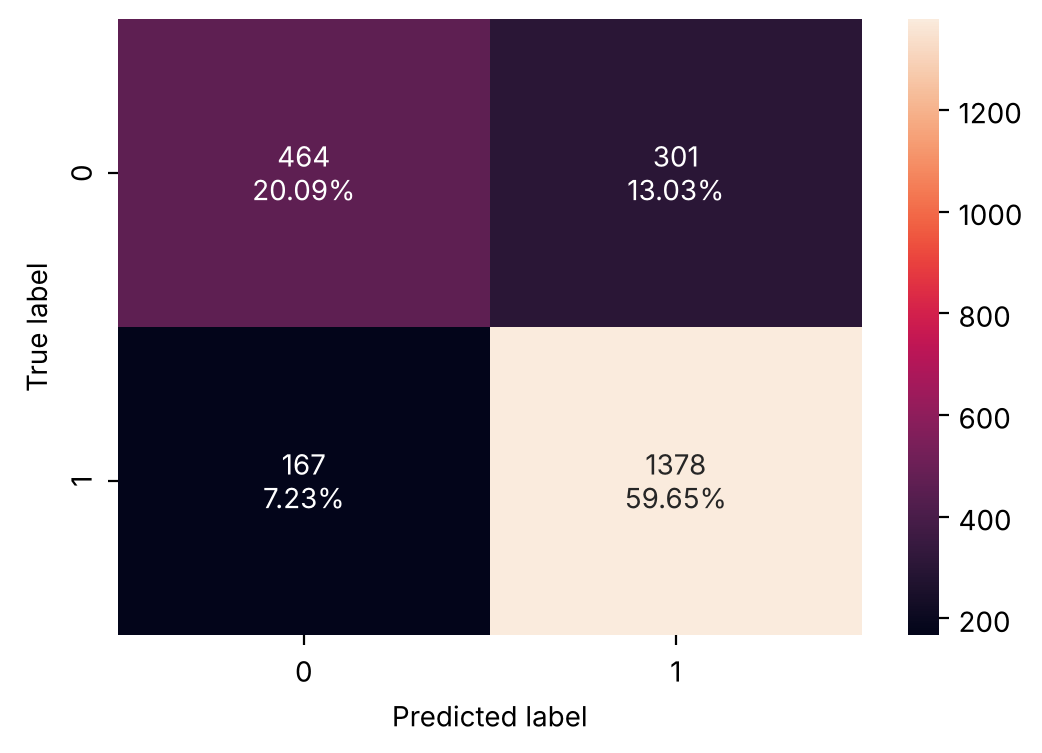

In [46]:
plot_confusion(lr, X_val, y_val)

In [47]:
print("Before oversampling, label 1:", sum(y_train == 1))
print("Before oversampling, label 0:", sum(y_train == 0))

smote = SMOTE(sampling_strategy=1, k_neighbors=5, random_state=1)
X_train_over, y_train_over = smote.fit_resample(X_train, y_train)

print("After oversampling, label 1:", sum(y_train_over == 1))
print("After oversampling, label 0:", sum(y_train_over == 0))
print("After oversampling, shape of X:", X_train_over.shape)
print("After oversampling, shape of y:", y_train_over.shape)

Before oversampling, label 1: 4632
Before oversampling, label 0: 2296
After oversampling, label 1: 4632
After oversampling, label 0: 4632
After oversampling, shape of X: (9264, 11)
After oversampling, shape of y: (9264,)


In [48]:
lr_over = LogisticRegression(random_state=1)
lr_over.fit(X_train_over, y_train_over)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

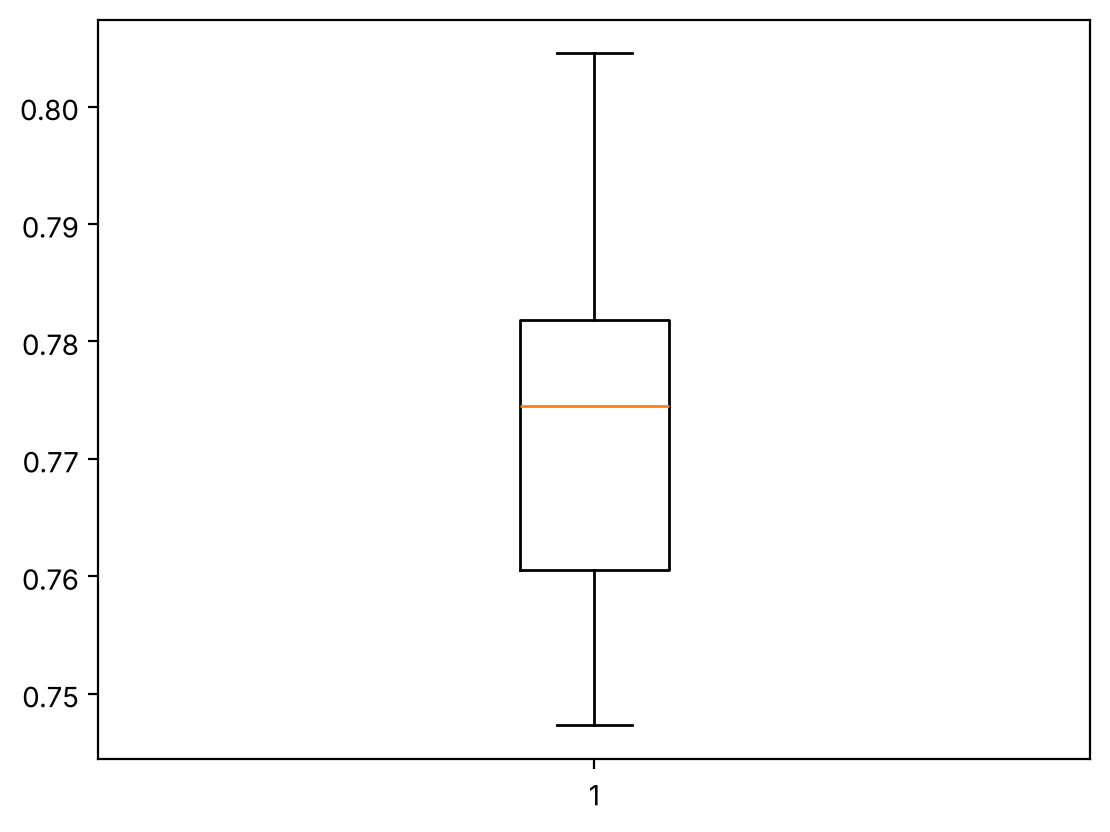

In [49]:
cv_over = cross_val_score(estimator=lr_over, X=X_train_over, y=y_train_over, scoring="recall", cv=kfold)
plt.boxplot(cv_over)
plt.show()

In [50]:
lr_over_train = get_scores(lr_over, X_train_over, y_train_over)
print("Training performance:")
lr_over_train

Training performance:


,Accuracy,Recall,Precision,F1
0,0.790587,0.771805,0.801929,0.786579


In [51]:
lr_over_val = get_scores(lr_over, X_val, y_val)
print("Validation performance:")
lr_over_val

Validation performance:


,Accuracy,Recall,Precision,F1
0,0.794372,0.792233,0.888244,0.837496


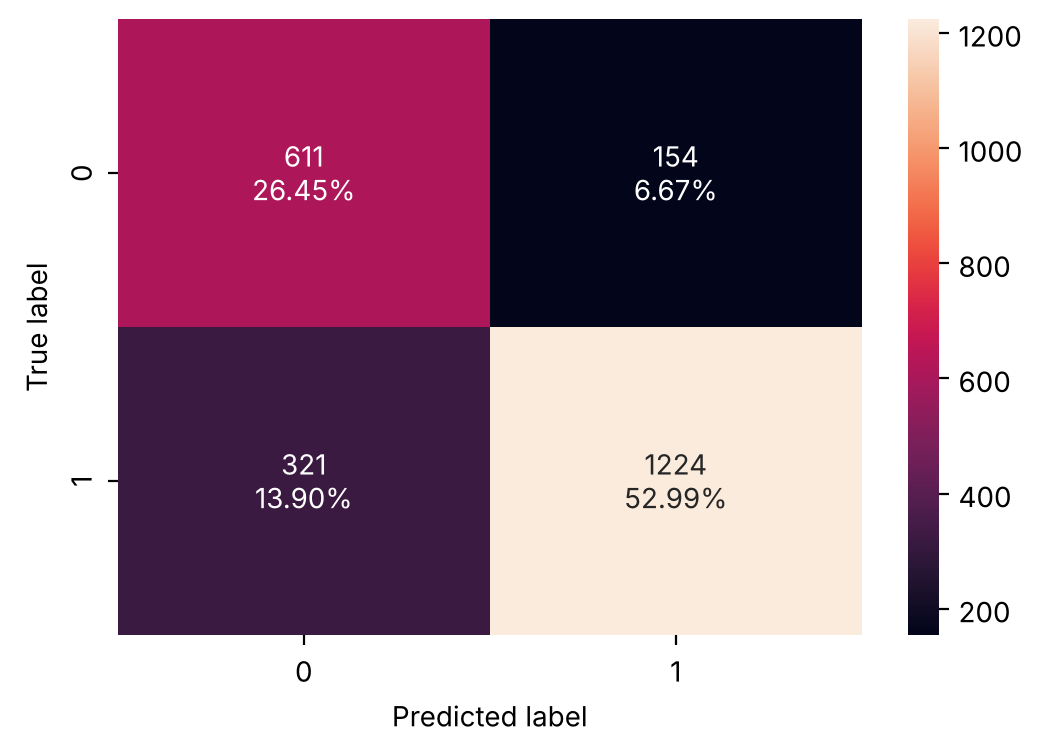

In [52]:
plot_confusion(lr_over, X_val, y_val)

In [53]:
lr_reg = LogisticRegression(random_state=1, solver="saga")
params = {"C": np.arange(0.1, 1.1, 0.1)}
grid = GridSearchCV(lr_reg, params, scoring="recall")
grid = grid.fit(X_train_over, y_train_over)
lr_reg = grid.best_estimator_
lr_reg.fit(X_train_over, y_train_over)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",np.float64(0.5)
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Sett

In [54]:
lr_reg_train = get_scores(lr_reg, X_train_over, y_train_over)
print("Training performance:")
lr_reg_train

Training performance:


,Accuracy,Recall,Precision,F1
0,0.790587,0.771805,0.801929,0.786579


In [55]:
lr_reg_val = get_scores(lr_reg, X_val, y_val)
print("Validation performance:")
lr_reg_val

Validation performance:


,Accuracy,Recall,Precision,F1
0,0.794372,0.792233,0.888244,0.837496


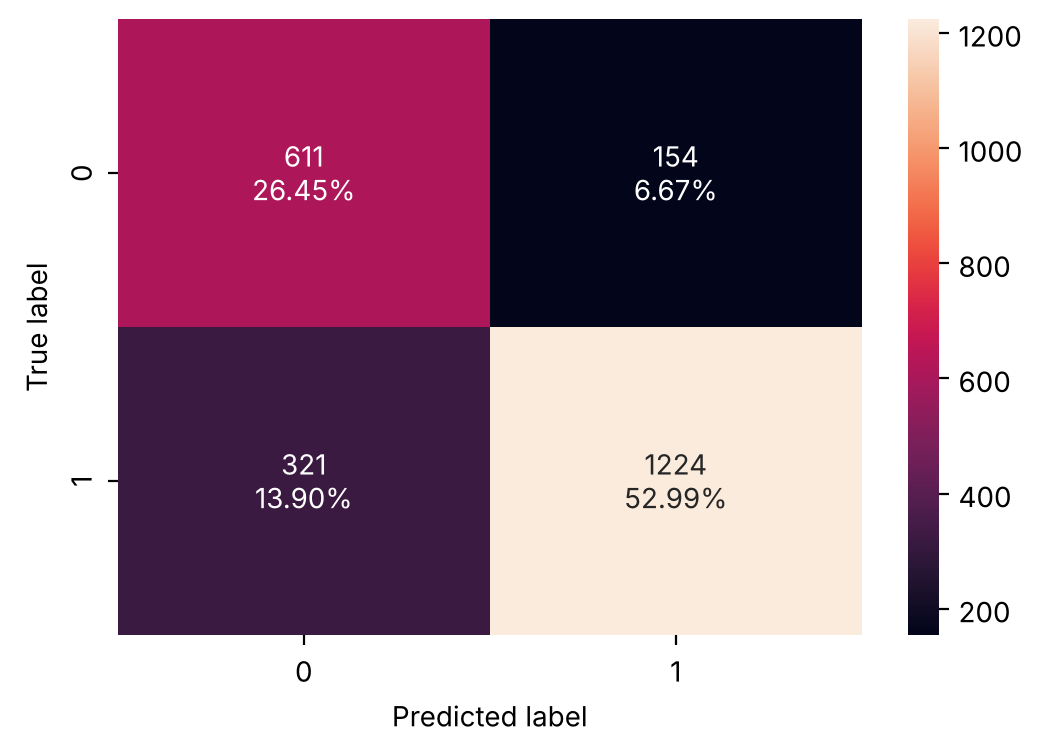

In [56]:
plot_confusion(lr_reg, X_val, y_val)

In [57]:
rus = RandomUnderSampler(random_state=1)
X_train_un, y_train_un = rus.fit_resample(X_train, y_train)

print("Before undersampling, label 1:", sum(y_train == 1))
print("Before undersampling, label 0:", sum(y_train == 0))
print("After undersampling, label 1:", sum(y_train_un == 1))
print("After undersampling, label 0:", sum(y_train_un == 0))
print("After undersampling, shape of X:", X_train_un.shape)
print("After undersampling, shape of y:", y_train_un.shape)

Before undersampling, label 1: 4632
Before undersampling, label 0: 2296
After undersampling, label 1: 2296
After undersampling, label 0: 2296
After undersampling, shape of X: (4592, 11)
After undersampling, shape of y: (4592,)


In [58]:
lr_under = LogisticRegression(random_state=1)
lr_under.fit(X_train_un, y_train_un)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

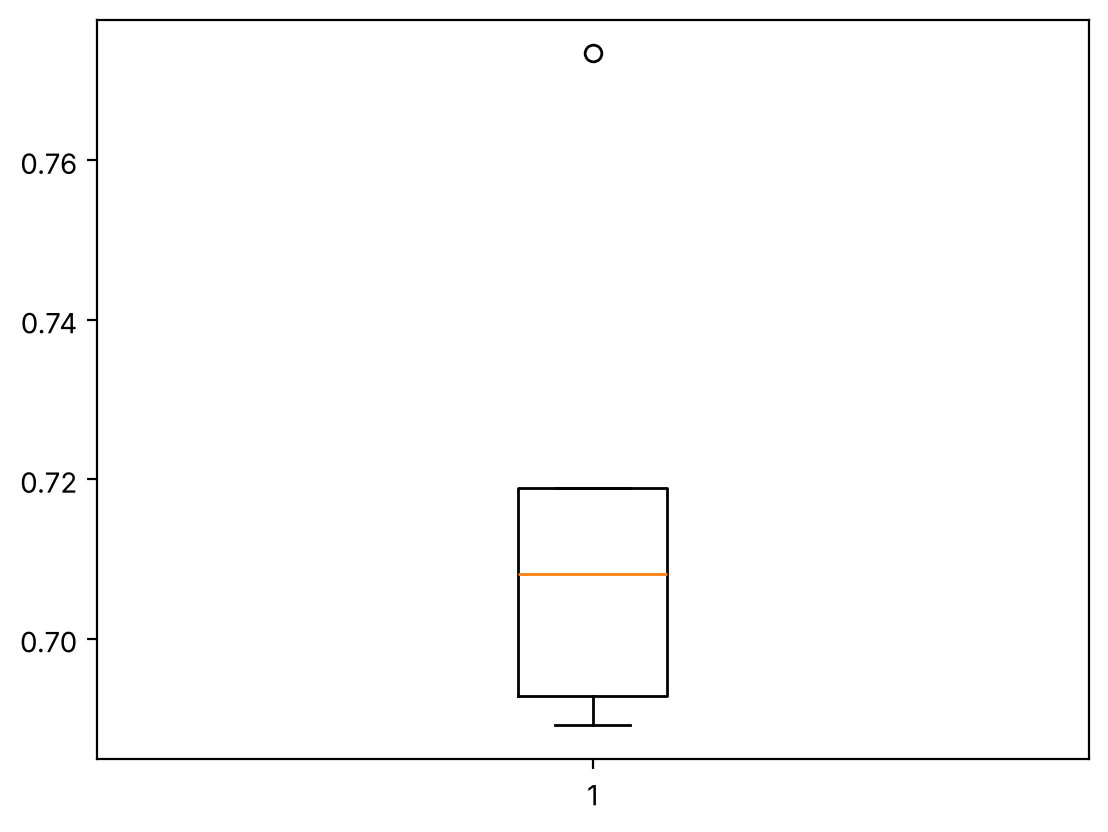

In [59]:
cv_under = cross_val_score(estimator=lr_under, X=X_train_un, y=y_train_un, scoring="recall", cv=kfold)
plt.boxplot(cv_under)
plt.show()

In [60]:
lr_under_train = get_scores(lr_under, X_train_un, y_train_un)
print("Training performance:")
lr_under_train

Training performance:


,Accuracy,Recall,Precision,F1
0,0.768075,0.708624,0.804251,0.753415


In [61]:
lr_under_val = get_scores(lr_under, X_val, y_val)
print("Validation performance:")
lr_under_val

Validation performance:


,Accuracy,Recall,Precision,F1
0,0.769264,0.739806,0.897174,0.810926


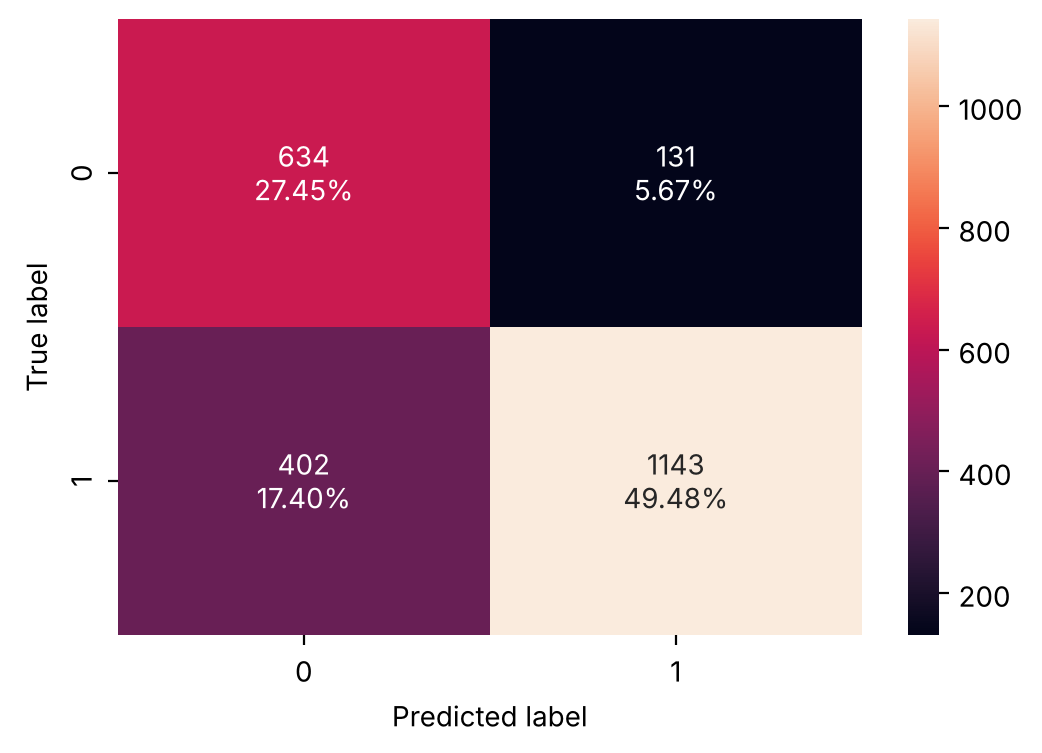

In [62]:
plot_confusion(lr_under, X_val, y_val)

In [63]:
model_names = [
    "Logistic Regression",
    "Logistic Regression with oversampled data",
    "Regularised Logistic Regression",
    "Logistic Regression with undersampled data",
]

train_compare = pd.concat(
    [lr_train.T, lr_over_train.T, lr_reg_train.T, lr_under_train.T], axis=1
)
train_compare.columns = model_names
print("Training performance comparison:")
train_compare

Training performance comparison:


,Logistic Regression,Logistic Regression with oversampled data,Regularised Logistic Regression,Logistic Regression with undersampled data
Accuracy,0.782621,0.790587,0.790587,0.768075
Recall,0.872409,0.771805,0.771805,0.708624
Precision,0.815375,0.801929,0.801929,0.804251
F1,0.842929,0.786579,0.786579,0.753415


In [64]:
val_compare = pd.concat(
    [lr_val.T, lr_over_val.T, lr_reg_val.T, lr_under_val.T], axis=1
)
val_compare.columns = model_names
print("Validation performance comparison:")
val_compare

Validation performance comparison:


,Logistic Regression,Logistic Regression with oversampled data,Regularised Logistic Regression,Logistic Regression with undersampled data
Accuracy,0.797403,0.794372,0.794372,0.769264
Recall,0.891909,0.792233,0.792233,0.739806
Precision,0.820727,0.888244,0.888244,0.897174
F1,0.854839,0.837496,0.837496,0.810926


In [65]:
lr_test = get_scores(lr, X_test, y_test)
print("Test performance:")
lr_test

Test performance:


,Accuracy,Recall,Precision,F1
0,0.789177,0.88342,0.816278,0.848523


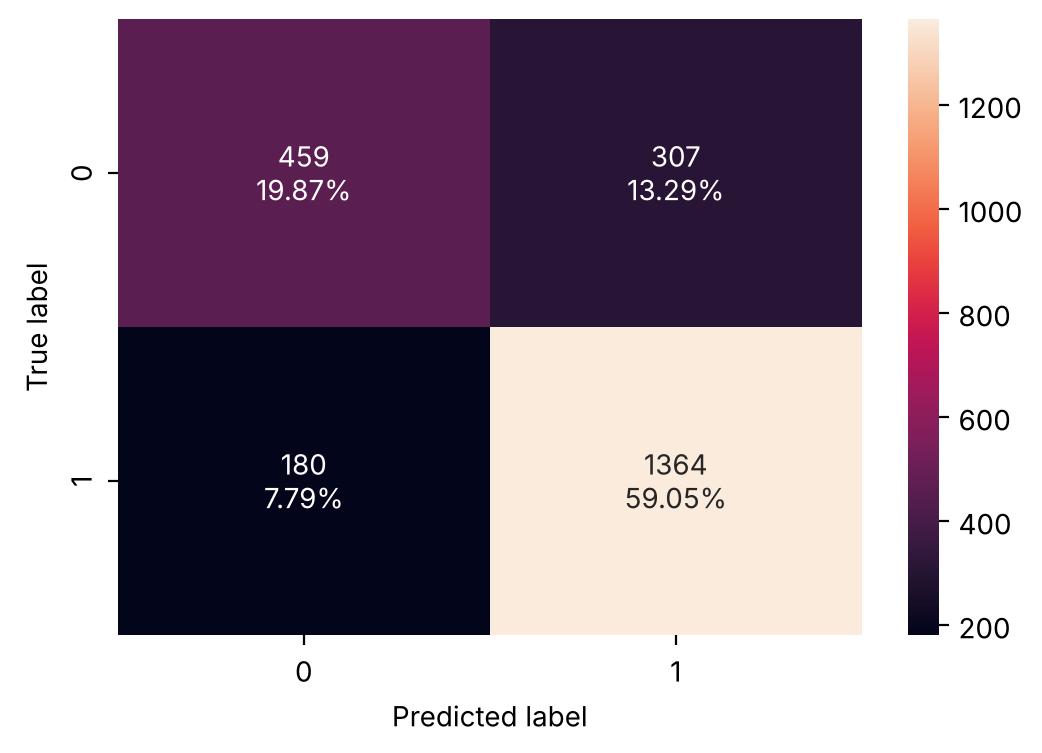

In [66]:
plot_confusion(lr, X_test, y_test)

In [67]:
coef_df = pd.DataFrame(
    np.append(lr.coef_, lr.intercept_),
    index=X_train.columns.tolist() + ["Intercept"],
    columns=["Coefficients"],
)
coef_df.T

,term_60 months,gender_Male,purpose_House,purpose_Medical,purpose_Other,purpose_Personal,purpose_Wedding,home_ownership_Own,home_ownership_Rent,age_>25,FICO_>500,Intercept
Coefficients,-2.033788,0.790446,0.086187,0.409481,-0.050275,0.171595,0.044048,0.103589,-0.089995,0.563389,-1.981912,1.165601


In [68]:
pd.set_option("display.max_columns", None)
odds = np.exp(lr.coef_[0])
pd.DataFrame(odds, X_train.columns, columns=["odds"]).T

,term_60 months,gender_Male,purpose_House,purpose_Medical,purpose_Other,purpose_Personal,purpose_Wedding,home_ownership_Own,home_ownership_Rent,age_>25,FICO_>500
odds,0.130839,2.204379,1.09001,1.506036,0.950968,1.187197,1.045032,1.109145,0.913936,1.756616,0.137805


In [69]:
perc_change = (np.exp(lr.coef_[0]) - 1) * 100
pd.DataFrame(perc_change, X_train.columns, columns=["change_odds%"]).T

,term_60 months,gender_Male,purpose_House,purpose_Medical,purpose_Other,purpose_Personal,purpose_Wedding,home_ownership_Own,home_ownership_Rent,age_>25,FICO_>500
change_odds%,-86.916105,120.437917,9.001019,50.603603,-4.903246,18.719705,4.503241,10.914457,-8.60642,75.661593,-86.219456


* FICO score and loan term are the main things linked to delinquency. Customers with low FICO score (300-500) and 36 months loans are the most delinquent.
* Gender also showed some effect in the model, while purpose and home ownership showed very little difference.
* Simple logistic regression gave the best result with a recall of about 0.88 on the test data.